# 02 – Symbolic controller: "visit A, then B, then target, always avoid C"

**Goal:** the prof gives a grid (size, obstacles, regions) and a task with an order. We build a controller that is
*correct by construction*: if the computer finds a solution, the robot is guaranteed to do the task without
touching anything (lecture *Symbolic control*, Saoud & Belamfedel Alaoui).

**The idea in one sentence:** turn the robot into a finite graph, write a "road sign" in every cell of the graph
(backwards from the goal), then let the robot follow the signs.

| Step | What | Lecture | Code |
|---|---|---|---|
| 1 | Grid + robot → finite graph (cells, commands, transitions, labels) | slides 39–44, TD3 Ex.1 | `abstraction.py` |
| 2 | Signs to reach the target while avoiding obstacles | "Reachability synthesis", Theorem 16, TD3 Ex.6 | `synthesis.py` |
| 3 | Memory for "A, then B, then target" | "Automata-based specifications", LTL lecture | `automaton.py` |
| 4 | Run it in the same simulator as the PID | slides 43–44 (concretization), "Imperfect measurements" | `controller.py` |

The prof's problem lives in `controllers/symbolic/problem.yaml` (the only file to edit for a new grid).
Our tuning lives in `controllers/symbolic/config_symbolic.yaml`.

In [1]:
import sys, copy, pathlib, time
sys.path.insert(0, str(pathlib.Path.cwd().parent))     # project root
import numpy as np, matplotlib.pyplot as plt, pandas as pd
from common.config import load_config
from common.runner import run
from common.plotting import plot_signals
from controllers.symbolic.abstraction import build_default
from controllers.symbolic.synthesis import reach_avoid, default_avoid
from controllers.symbolic.automaton import Automaton, product_reach_avoid, SequenceRunner
from controllers.symbolic.controller import SymbolicController, task_path
from controllers.symbolic.viz import plot_world, plot_transition

cfg = load_config()
t0 = time.time()
abst = build_default(cfg)          # step 1, all at once (a few seconds)
world = abst.world
print(f'Graph built in {time.time() - t0:.1f} s')
print('Task:', world.spec)

Graph built in 5.2 s
Task: {'visit_in_order': ['A', 'B', 'target'], 'always_avoid': ['C']}


## Step 1a – The map

Grey = where the robot's **centre** may not go. Obstacles and walls are grown by the robot radius (10 cm), plus a
little sensor error, so "centre outside the grey" means "body does not touch".
C is not grey here: it is only forbidden because the task says so (step 3).

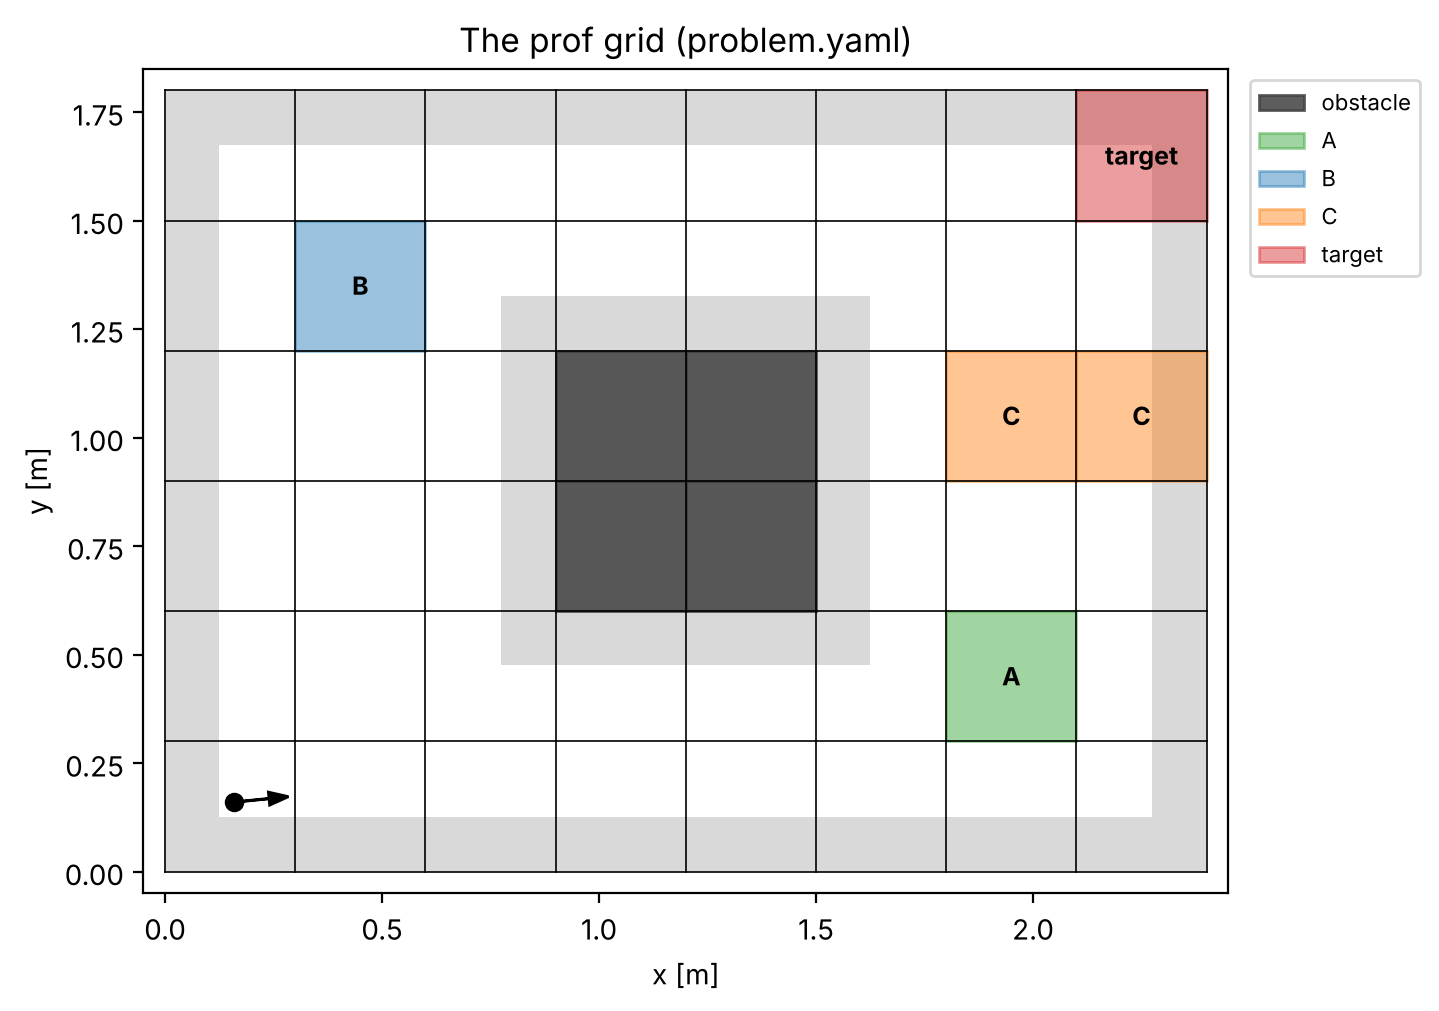

In [2]:
ax = plot_world(world, abst=abst); ax.set_title('The prof grid (problem.yaml)'); plt.show()

## Step 1b – The graph

* **States (Q):** one state = one small cell (2.5 cm) + one heading slice (11.25°). The heading matters because
  "drive forward" goes somewhere different when facing east or north.
* **Commands (P):** a small menu of 14 (speed, turn rate) pairs. Each one is a 1.5 s **move**: speed up, cruise,
  slow down, stop.
* **Transitions (F):** for a state and a command, all the states the robot *might* land in, from anywhere in the
  cell, with sensor error and disturbance. It is pessimistic on purpose: it may list too many, never too few.

In [3]:
pd.Series(abst.summary(), name='value').to_frame()

,value
small cell [m],0.025
heading slice [deg],11.25
grid of small cells,"(96, 72, 32)"
"|Q| (states, + Q_OUT)",221185
|P| (inputs),14
tau [s],1.5
measurement error,"[0.005, 0.005, 0.01]"
"mean successors per (q,p)",43.9
"share of (q,p) that may leave the grid",0.111


**One state, three commands.** Black square = the start cell. Red dashes = the box where the robot can end up.
Blue = the landing cells, i.e. F. Green dots = the **swept area**: everything the robot can cross *during*
the move, used to make sure it never clips an obstacle on the way.

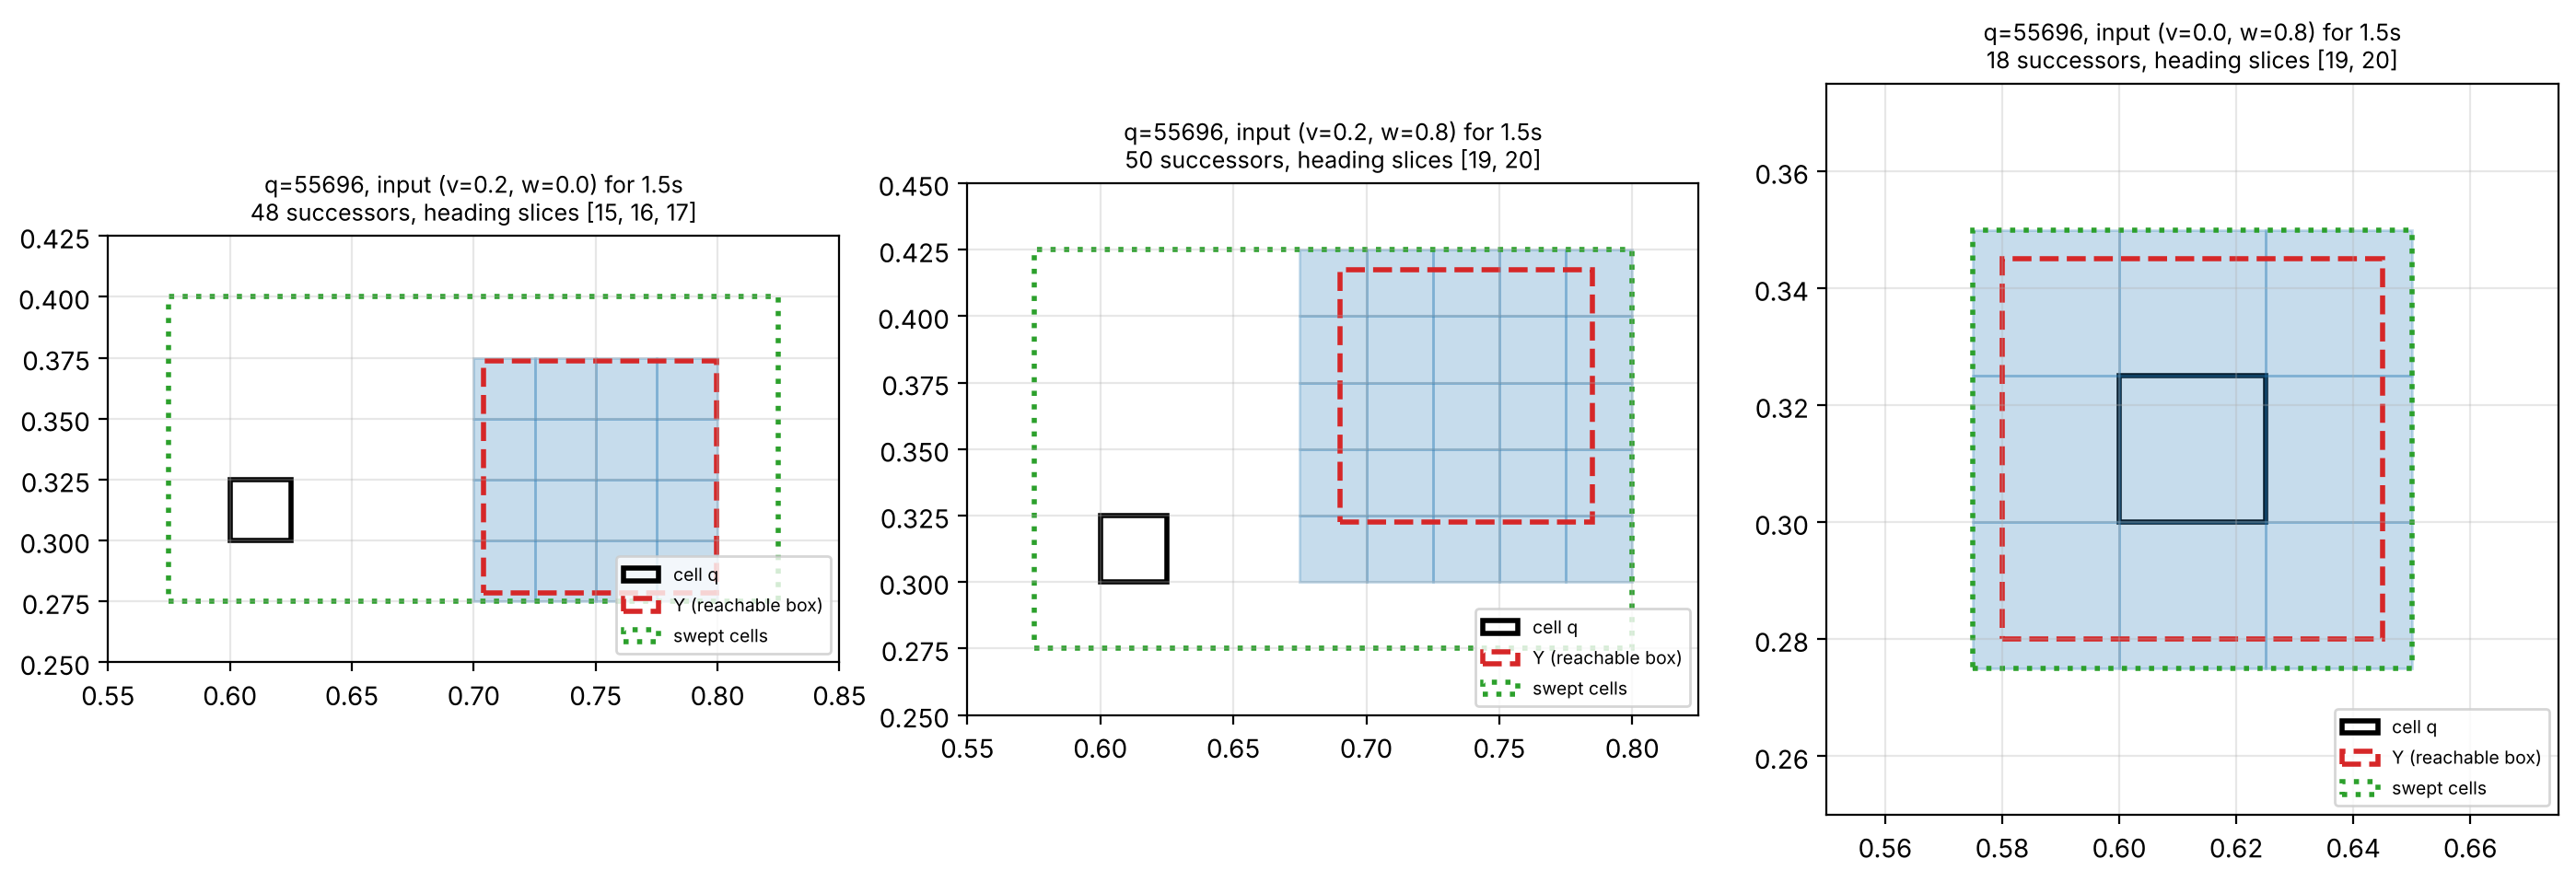

In [4]:
q_demo = abst.quantize([0.6, 0.3, 0.0])
fig, axs = plt.subplots(1, 3, figsize=(14, 5))
for ax, u in zip(axs, [(0.2, 0.0), (0.2, 0.8), (0.0, 0.8)]):
    plot_transition(abst, q_demo, abst.inputs.index(u), ax)
fig.tight_layout(); plt.show()

**The move itself.** A real robot cannot change speed instantly (the simulator has acceleration limits and a
command delay). So every move ramps up, cruises and stops. The robot then stands still for a moment and
averages 9 position readings before choosing the next move: that divides the sensor noise by 3.

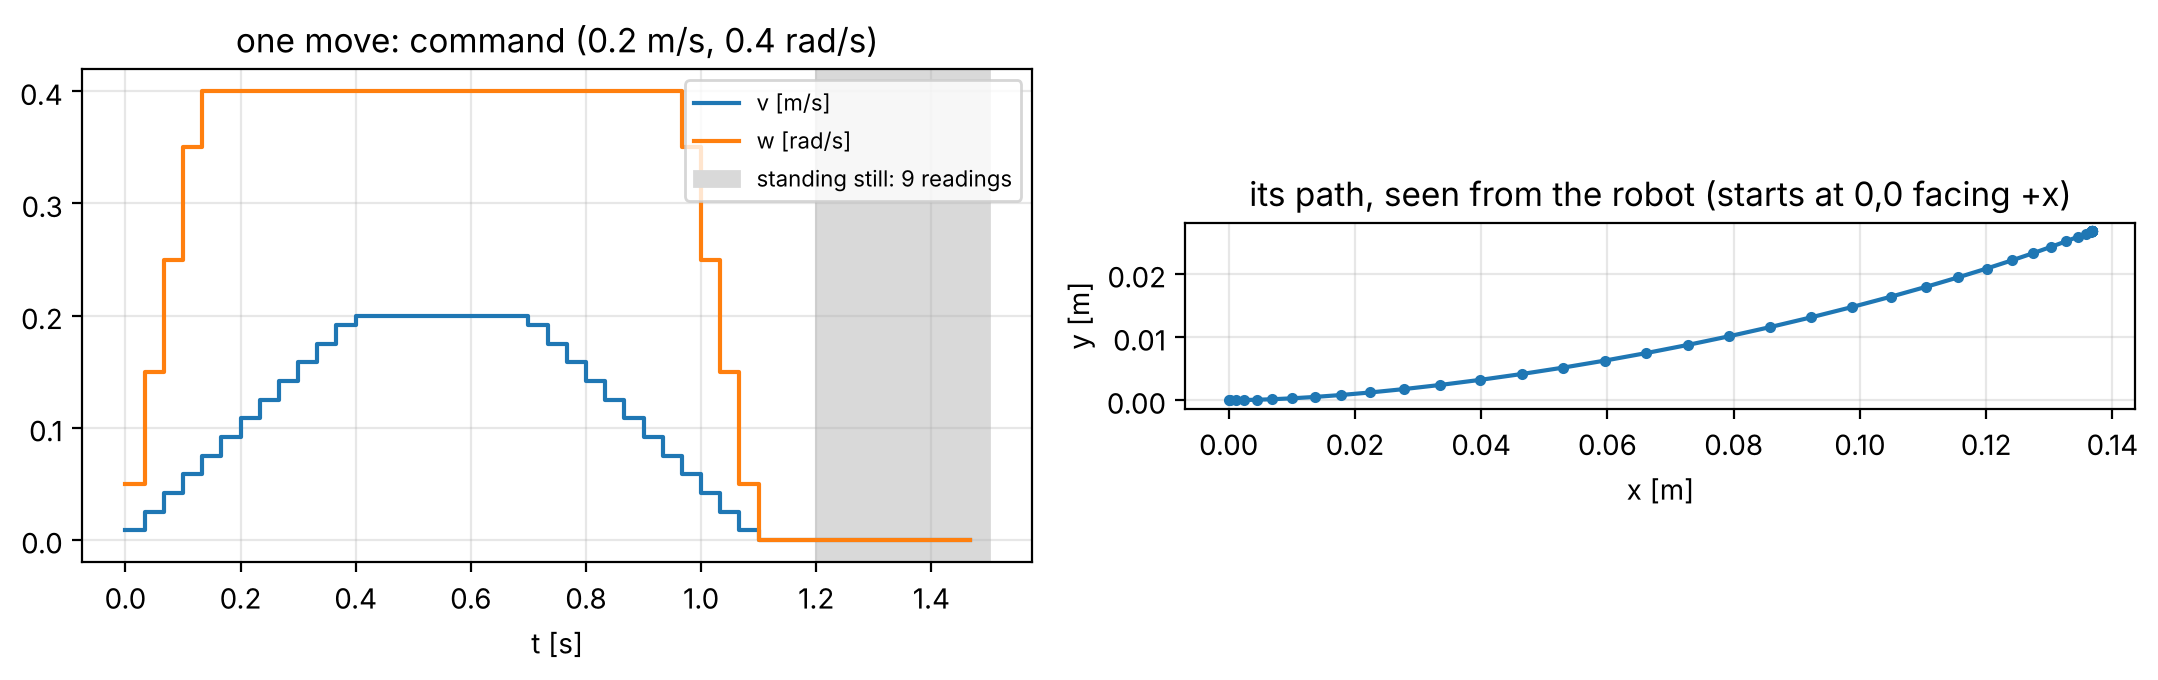

In [5]:
mv = abst.moves[abst.inputs.index((0.2, 0.4))]
t = np.arange(len(mv.vs)) * abst.dt
fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
axs[0].step(t, mv.vs, where='post', label='v [m/s]'); axs[0].step(t, mv.ws, where='post', label='w [rad/s]')
axs[0].axvspan(t[-abst.n_avg], t[-1] + abst.dt, color='0.85', label='standing still: 9 readings')
axs[0].set_xlabel('t [s]'); axs[0].set_title('one move: command (0.2 m/s, 0.4 rad/s)'); axs[0].legend(fontsize=8)
axs[1].plot(mv.pts[:, 0], mv.pts[:, 1], '.-'); axs[1].set_aspect('equal')
axs[1].set_title('its path, seen from the robot (starts at 0,0 facing +x)'); axs[1].set_xlabel('x [m]'); axs[1].set_ylabel('y [m]')
for a in axs: a.grid(alpha=.3)
fig.tight_layout(); plt.show()

## Step 2 – Road signs to the target (reach + avoid)

**Moment 1 (computer, once, backwards):** start at the target, and ring by ring write a sign in every cell that
has a command *sure* to land in an already-signed cell, without its swept area touching anything forbidden.

**Moment 2 (robot, forwards):** read your cell, read its sign, do that move, repeat.

In [6]:
t0 = time.time()
res2 = reach_avoid(abst, ['target'], default_avoid(abst))
print(f"{res2['n_rings']} rings in {time.time() - t0:.1f} s; {int(res2['win'].sum())} states have a sign")

76 rings in 9.1 s; 88056 states have a sign


**The ripples.** Left: the ring number of each cell (lowest over headings) = how many moves away from the target
it is, at most. Dark = close. The signs spread out from the target, around the obstacle, and stop where it is
too tight to pass safely (for example the narrow gap next to C). Right: how many new states each ring adds.

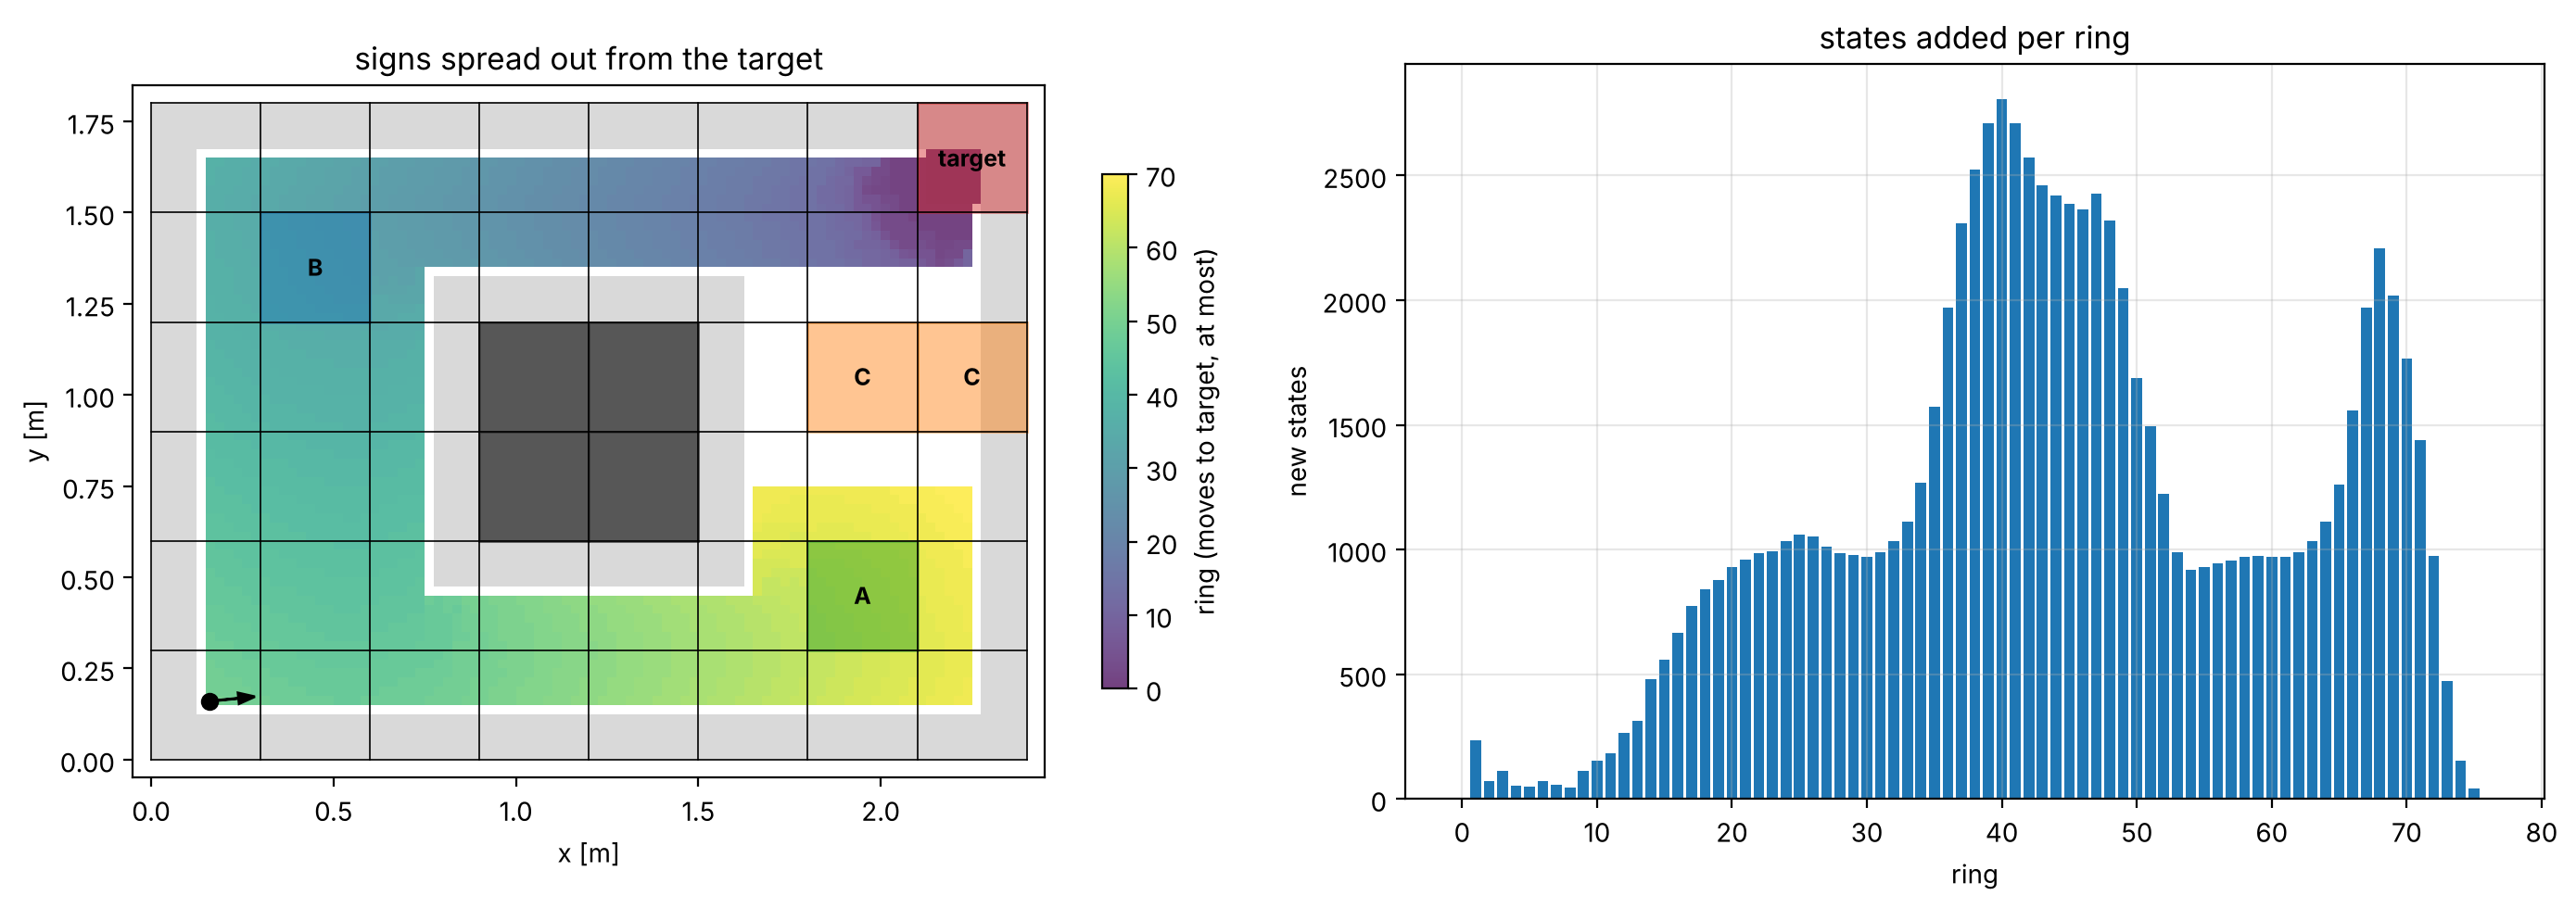

In [7]:
ring = res2['ring'].reshape(abst.nx, abst.ny, abst.nth).astype(float)
ring[ring < 0] = np.nan
best = np.nanmin(np.where(np.isnan(ring), np.inf, ring), axis=2); best[np.isinf(best)] = np.nan
xmin, ymin, xmax, ymax = world.bounds
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
plot_world(world, axs[0], abst=abst)
im = axs[0].imshow(best.T, origin='lower', extent=(xmin, xmax, ymin, ymax), cmap='viridis', alpha=0.75)
fig.colorbar(im, ax=axs[0], shrink=0.7, label='ring (moves to target, at most)')
axs[0].set_title('signs spread out from the target'); axs[0].get_legend().remove()
counts = np.bincount(res2['ring'][res2['ring'] > 0])
axs[1].bar(np.arange(len(counts)), counts); axs[1].set_xlabel('ring'); axs[1].set_ylabel('new states'); axs[1].grid(alpha=.3)
axs[1].set_title('states added per ring'); fig.tight_layout(); plt.show()

## Step 3 – Memory: A, then B, then target, always avoid C

In the same cell the robot must do different things depending on what it already visited. So it carries a tiny
memory machine (an **automaton**) and there is one map of signs per mode. The maps are written backwards
(target map first) and "arrived at B" only counts where the target map already has a sign.

In [8]:
aut = Automaton.from_spec(world.spec)
print(aut.describe())
t0 = time.time()
res3 = product_reach_avoid(abst, aut, default_avoid(abst))
print(f"\nSigns for all modes written in {time.time() - t0:.0f} s")

  0: go to A         inside A -> go to B
  1: go to B         inside B -> go to target
  2: go to target    inside target -> done
  3: done            (task finished)



Signs for all modes written in 35 s


**The three maps.** Green = cells with a sign in that mode. Each map leads to its own goal and never into C.

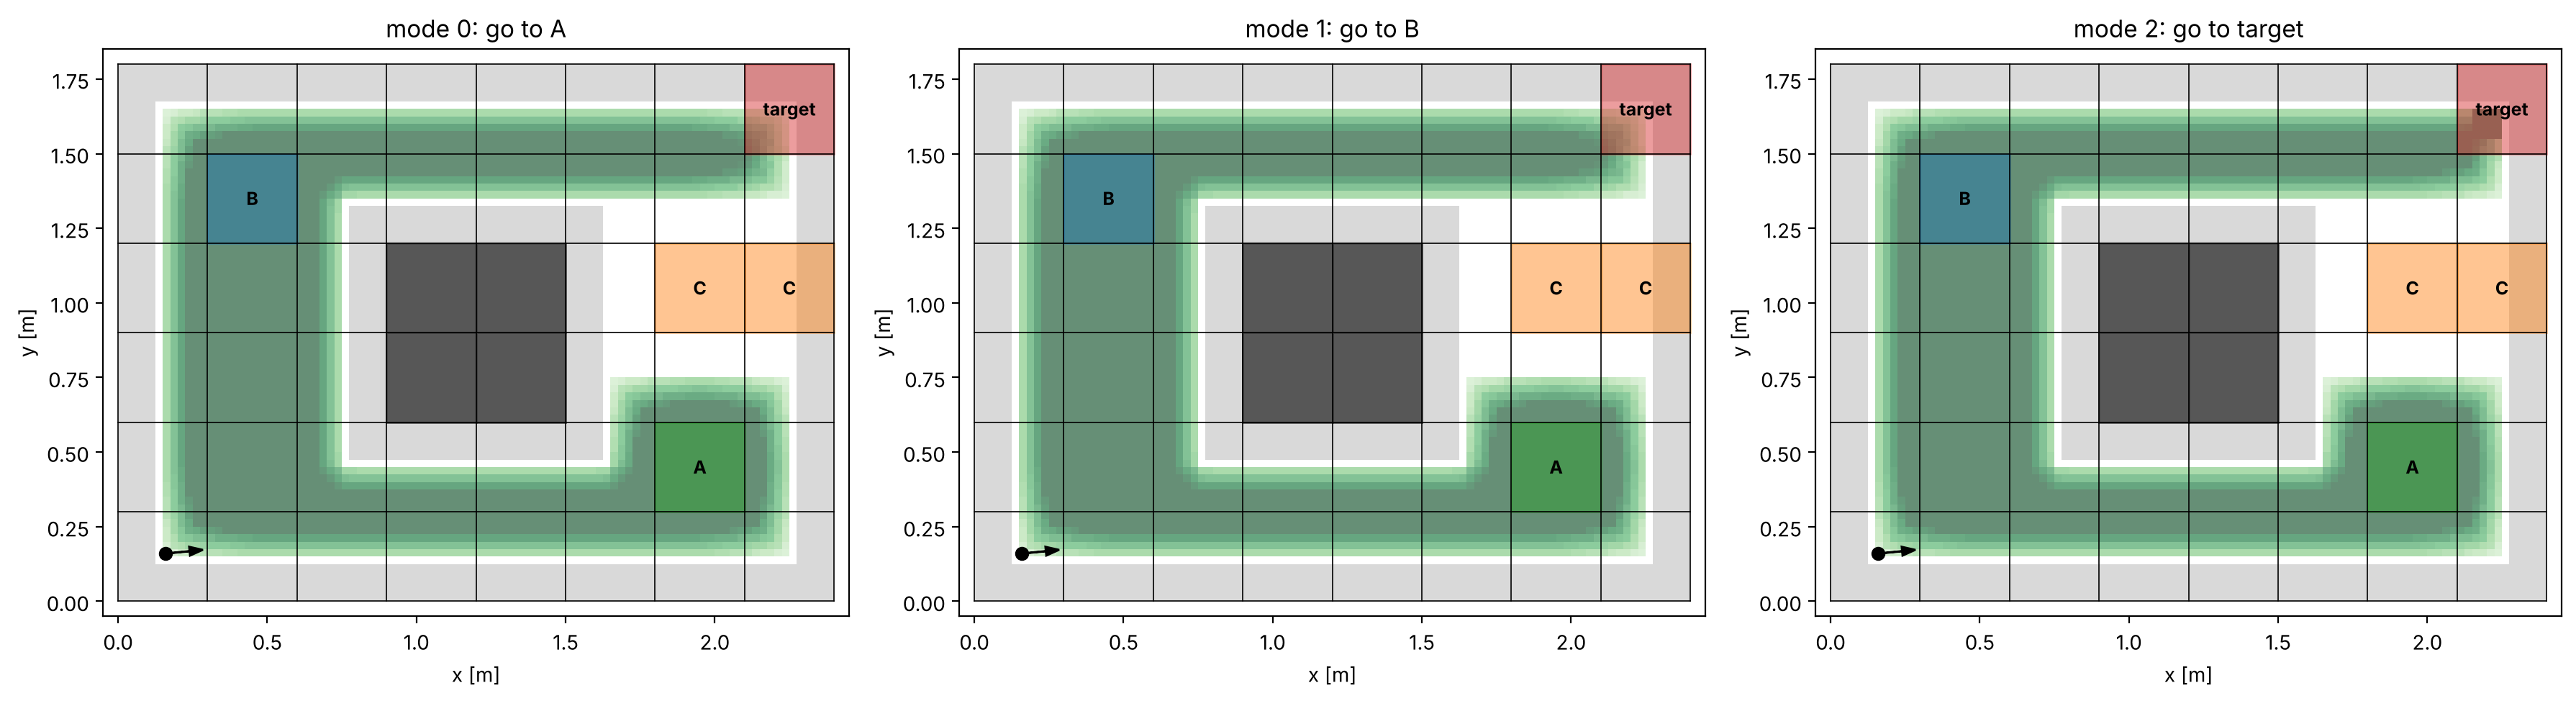

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(18, 5))
for m, ax in enumerate(axs):
    share = res3['win'][m].reshape(abst.nx, abst.ny, abst.nth).mean(axis=2)
    plot_world(world, ax, abst=abst); ax.get_legend().remove()
    ax.imshow(np.where(share > 0, share, np.nan).T, origin='lower', extent=(xmin, xmax, ymin, ymax),
              cmap='Greens', vmin=0, vmax=1, alpha=0.6)
    ax.set_title(f'mode {m}: {aut.names[m]}')
fig.tight_layout(); plt.show()

## Step 4 – In the repo's simulator (same as the PID)

`SymbolicController` follows the same interface as `PIDPathTracker` (`reset`, `step(pose, t) -> (v, w)`,
`done`), so it runs through `common/runner.py` with acceleration limits, command delay and noisy pose.
The signs are cached in `outputs/symbolic_cache/`, so this is fast after the first time.

Signs loaded from signs_99ff165151f5.npz
done=True, time=72.3 s, moves=48


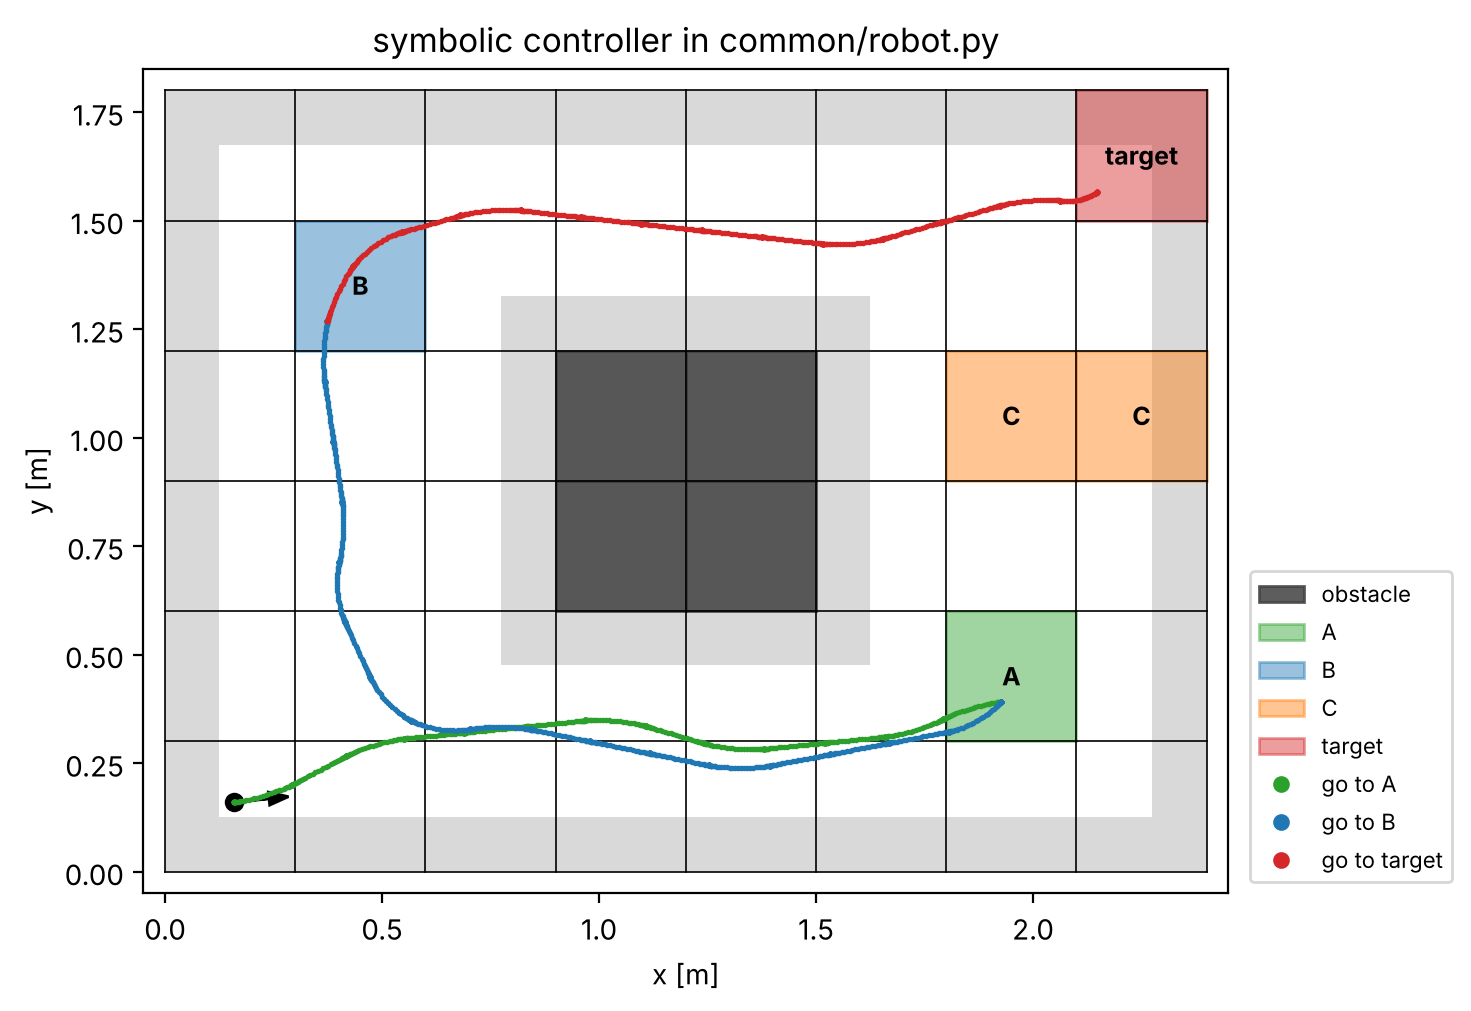

In [10]:
ctrl = SymbolicController(cfg)
c = copy.deepcopy(cfg); c['sim']['max_time'] = 300.0        # the task is long (~45 moves of 1.5 s)
log = run(ctrl, task_path(world), c, start_pose=world.start_pose)
modes = np.array(ctrl.mode_log)
print(f"done={ctrl.done}, time={log['t'][-1]:.1f} s, moves={len(ctrl.move_log)}")

ax = plot_world(world, abst=abst)
for m, col in zip(range(3), ['tab:green', 'tab:blue', 'tab:red']):
    sel = modes == m
    ax.plot(log['x'][sel], log['y'][sel], '.', ms=2, color=col, label=aut.names[m])
ax.legend(loc='lower left', bbox_to_anchor=(1.01, 0), fontsize=8, markerscale=5)
ax.set_title('symbolic controller in common/robot.py'); plt.show()

**Speeds over time.** Every move is a little hill: ramp up, cruise, ramp down, stand still (that is when the
readings are averaged). The actual speeds follow the commands with the delay of the simulator.

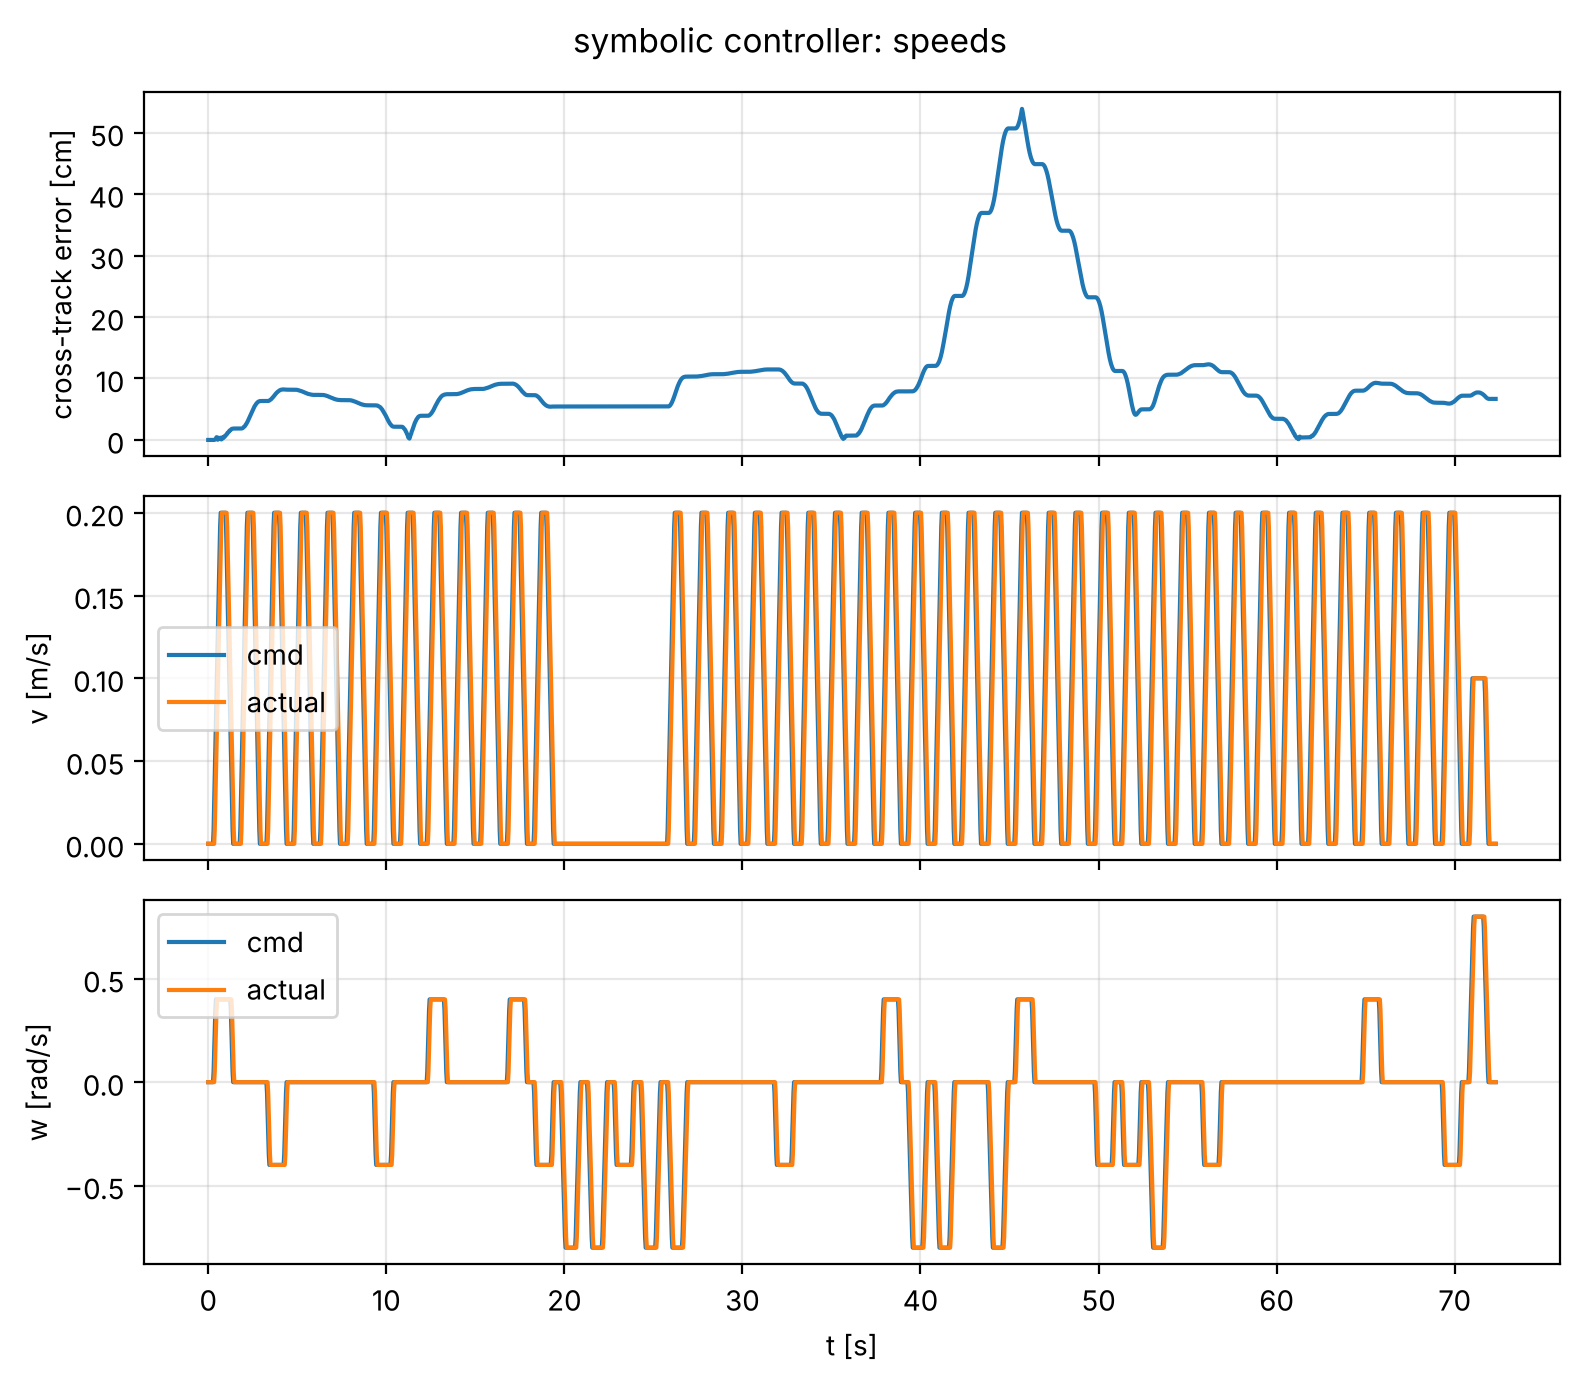

In [11]:
plot_signals(log, 'symbolic controller: speeds'); plt.show()

**Repeatability with different sensor noise.** Same grid, same signs, 10 different noise seeds. The route can
differ a little, but every run must finish in order and keep a positive clearance (distance between the robot's
body and the nearest obstacle, C or wall).

In [12]:
forbidden = world.rects('obstacle') + [r for n in world.spec.get('always_avoid', []) for r in world.rects(n)]
def clearance(x, y):
    d = [x - xmin, y - ymin, xmax - x, ymax - y]
    for (a, b, cc, e) in forbidden:
        d.append(np.hypot(max(a - x, 0, x - cc), max(b - y, 0, y - e)))
    return min(d) - abst.r_robot

rows = {}
for seed in range(10):
    c = copy.deepcopy(cfg); c['noise']['seed'] = seed; c['sim']['max_time'] = 300.0
    l = run(ctrl, task_path(world), c, start_pose=world.start_pose)
    m = np.array(ctrl.mode_log)
    rows[seed] = {'done in order': bool(ctrl.done and np.all(np.diff(m) >= 0)), 'time_s': l['t'][-1],
                  'moves': len(ctrl.move_log), 'min_clearance_cm': 100 * min(clearance(x, y) for x, y in zip(l['x'], l['y']))}
pd.DataFrame(rows).T.round(1)

,done in order,time_s,moves,min_clearance_cm
0,True,72.3,48,6.0
1,True,67.8,45,6.0
2,True,70.8,47,6.0
3,True,69.3,46,6.0
4,True,69.3,46,6.0
5,True,69.3,46,6.0
6,True,69.3,46,6.0
7,True,70.8,47,6.0
8,True,67.8,45,6.0
9,True,69.3,46,6.0


## When the prof gives the real grid

1. Edit `controllers/symbolic/problem.yaml`: `cols`, `rows`, `cell_size` (= arena width ÷ cols), obstacles,
   regions, start pose and `spec`.
2. Re-run this notebook (or `tests/check_symbolic_step1..4.py`).
3. If a step says **no solution**: the start may be too close to a wall or a cell edge, or corridors are too
   narrow for the margins. Try smaller cells (`subdiv`) or more commands in `config_symbolic.yaml`.
4. Before the real robot: measure `robot_radius`, check that `origin` matches `/robot_pose`, and keep
   `disturbance` as a safety margin.